# Forecasting Monthly Tourist Arrivals in Sri Lanka with Ensemble Machine Learning
### Bagging, boosting, voting, stacking and time-series hybrids, and *why* they behave as they do

**Research question:** Which ensemble methods forecast monthly tourist arrivals to Sri Lanka most accurately, how do months, seasons and a time-series trend change the answer, and why?

**Objectives**
1. Compare **bagging** (Random Forest, Extra Trees, Bagging), **boosting** (AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost) and **combining** methods (Voting, Stacking).
2. Merge them with a **trend / time-series model** (hybrid models, including SARIMA) and use **month and monsoon-season** features.
3. Test whether the ranking is **reliable** (rolling backtest) and **explain** the results (feature tests, permutation importance, SHAP, error analysis).

**Data (all Sri Lankan, official sources):** monthly tourist arrivals from the Sri Lanka Tourism Development Authority (SLTDA) and the monthly average USD/LKR exchange rate from the Central Bank of Sri Lanka (CBSL), January 2010 to July 2026 (199 months).

**How to read this notebook:** every code cell has a text cell before or after it that says *what it does*, *why we do it* and *what the result means*. Numbers quoted in the text come from one full run; yours may differ slightly (library versions), but the conclusions should be the same.

## 1. Setup

In [1]:
!pip install -q shap catboost xgboost lightgbm statsmodels

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
from matplotlib.patches import Patch

## 2. Data
**Sources and how the dataset was built**
- **Arrivals:** monthly tables from SLTDA Annual Statistical Reports (2019 and 2020 editions, covering 2010 to 2020), the December 2022 monthly report (2021 and 2022), the Annual Statistical Report 2024 (2023), the December 2025 monthly report (2024 and 2025) and the July 2026 monthly report (January to July 2026).
- **Exchange rate:** CBSL "Monthly average spot exchange rates" (LKR per USD).
- **Validation:** for every year, the sum of the 12 monthly values was compared with the yearly total printed in the SLTDA reports. All years match, except that one December 2020 value (393 arrivals) was read from a second table of the same report.
- One source inconsistency: March 2018 is 233,382 in the 2019 annual report and 233,282 in a later report. We used 233,382 because it makes the year add up to the official total.

**Load the data.** If you have uploaded the CSV to GitHub and set `DATA_URL` below, it loads directly. Otherwise Colab asks you to upload the file.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/YOUR_USERNAME/YOUR_REPO/main/data/tourism_monthly_2010_2026.csv"
try:
    df = pd.read_csv(DATA_URL, parse_dates=["date"])
    print("Loaded from GitHub")
except Exception:
    from google.colab import files
    print("GitHub link not set yet: please upload tourism_monthly_2010_2026.csv")
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[-1], parse_dates=["date"])   # uses the file you just uploaded

df = df.sort_values("date").reset_index(drop=True)
print(df.shape)
df.head()

GitHub link not set yet: please upload tourism_monthly_2010_2026.csv


Saving tourism_monthly_2010_2026.csv to tourism_monthly_2010_2026.csv
(199, 3)


,date,arrivals,usd_lkr
0,2010-01-01,50757,114.354533
1,2010-02-01,57300,114.536116
2,2010-03-01,52352,114.182491
3,2010-04-01,38300,113.884759
4,2010-05-01,35213,113.741832


`parse_dates` makes `date` a real date (needed for time-series work). Next, basic quality checks.

In [4]:
print("Rows, columns:", df.shape)
print("Period:", df["date"].min().date(), "to", df["date"].max().date())
print("Missing values per column:")
print(df.isna().sum())
df.describe()

Rows, columns: (199, 3)
Period: 2010-01-01 to 2026-07-01
Missing values per column:
date        0
arrivals    0
usd_lkr     0
dtype: int64


,date,arrivals,usd_lkr
count,199,199.000000,199.000000
mean,2018-04-01 11:34:40.402010112,121607.050251,193.588266
min,2010-01-01 00:00:00,0.000000,109.502420
25%,2014-02-15 00:00:00,71240.500000,130.973729
50%,2018-04-01 00:00:00,118743.000000,156.135400
75%,2022-05-16 12:00:00,167364.000000,292.897172
max,2026-07-01 00:00:00,279328.000000,363.394048
std,NaN,69587.080006,80.210611


**Reading the result:** 199 rows and no missing values. `arrivals` ranges from 0 (COVID border closure) to about 280,000 per month, so the data contains big shocks, not only a smooth trend. `usd_lkr` rises from about 114 to over 330 rupees per dollar.

## 3. Exploring the data

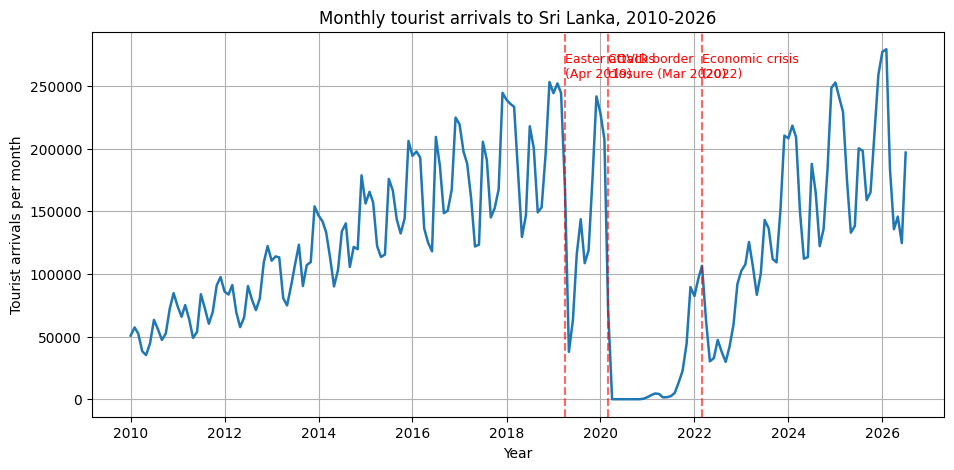

In [5]:
fig, ax = plt.subplots()
ax.plot(df["date"], df["arrivals"], color="tab:blue", linewidth=1.8)

events = {
    "2019-04-01": "Easter attacks\n(Apr 2019)",
    "2020-03-01": "COVID border\nclosure (Mar 2020)",
    "2022-03-01": "Economic crisis\n(2022)",
}
for d, label in events.items():
    ax.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.6)
    ax.text(pd.Timestamp(d), df["arrivals"].max()*0.92, label, fontsize=9, ha="left", color="red")

ax.set_title("Monthly tourist arrivals to Sri Lanka, 2010-2026")
ax.set_xlabel("Year")
ax.set_ylabel("Tourist arrivals per month")
plt.show()

**What we see:**
1. **Trend:** strong growth from 2010 to 2018, after the end of the war.
2. **Shocks:** a fall after the April 2019 Easter attacks, then almost zero from April 2020 (COVID border closure).
3. **Recovery:** slow after 2021, disturbed again by the 2022 economic crisis, then a strong return in 2023 to 2025.
4. **Seasonal waves** inside each year (next chart).

No model can *predict* a pandemic from past data, so these periods will matter when we explain the results.

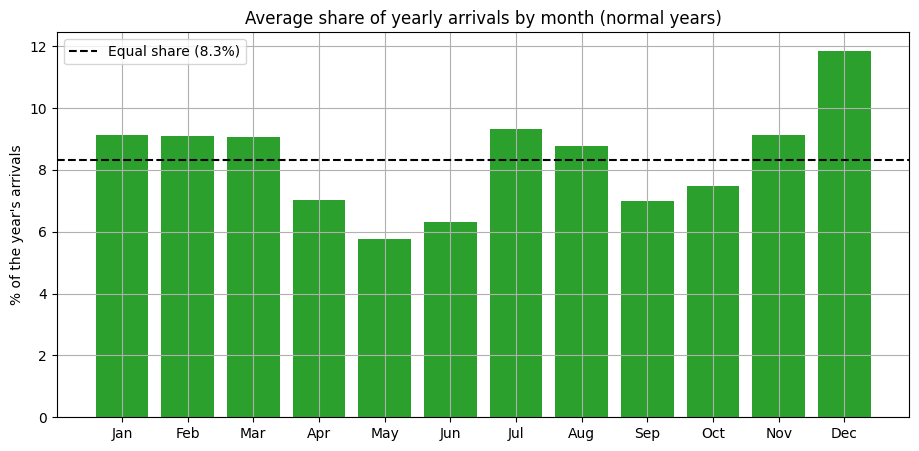

,share_pct
month,
1,9.1
2,9.1
3,9.1
4,7.0
5,5.7
6,6.3
7,9.3
8,8.8
9,7.0


In [6]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

normal = df[~df["year"].isin([2019, 2020, 2021, 2022, 2026])]   # ignore shock years and the incomplete year

# Share of each month within its own year, so growth over time does not hide the pattern
yearly_total = normal.groupby("year")["arrivals"].transform("sum")
normal = normal.assign(share_pct = normal["arrivals"] / yearly_total * 100)

season = normal.groupby("month")["share_pct"].mean()

month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots()
ax.bar(month_names, season.values, color="tab:green")
ax.axhline(100/12, color="black", linestyle="--", label="Equal share (8.3%)")
ax.set_title("Average share of yearly arrivals by month (normal years)")
ax.set_ylabel("% of the year's arrivals")
ax.legend()
plt.show()
season.round(1)

**Months above the dashed line (8.3%) are busy:** December (about 12%), then January, February, March and November (about 9% each), and July (about 9%). **Quiet months:** May and June (about 6%), April and September (about 7%), October (about 7.5%). There is a main peak from November to March and a smaller second peak in July to August.

*Possible reasons (from tourism knowledge, not proven by this data):* dry weather on the west and south coasts in winter, European holidays at year end, and the south-west monsoon rains in April to June.

**Why this matters:** it shows that *month* and *season* carry information, so we will turn them into model features.

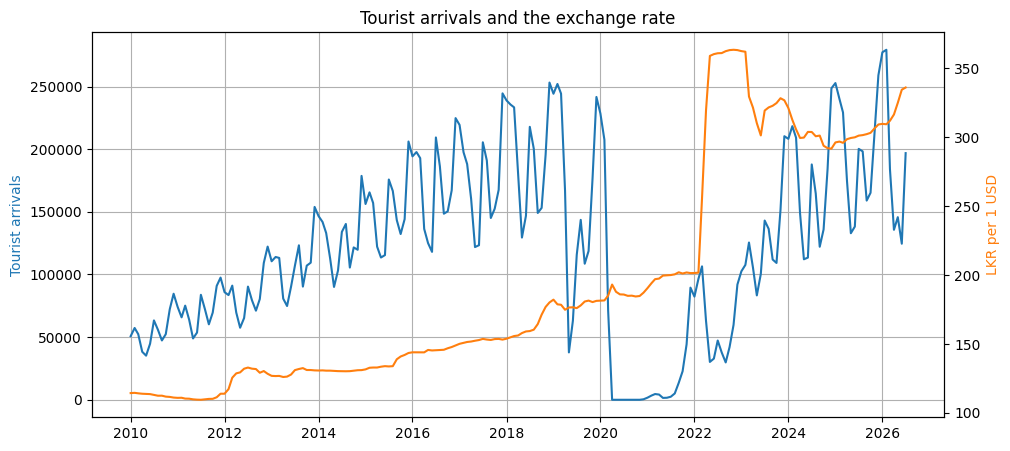

In [7]:
fig, ax1 = plt.subplots()
ax1.plot(df["date"], df["arrivals"], color="tab:blue", label="Arrivals")
ax1.set_ylabel("Tourist arrivals", color="tab:blue")

ax2 = ax1.twinx()                      # second y-axis on the right
ax2.plot(df["date"], df["usd_lkr"], color="tab:orange", label="USD/LKR")
ax2.set_ylabel("LKR per 1 USD", color="tab:orange")
ax2.grid(False)

ax1.set_title("Tourist arrivals and the exchange rate")
plt.show()

The exchange rate climbs steadily with a sharp jump in 2022, while arrivals bounce around. There is no simple straight-line link. **Careful:** both series trend upward, so they can look related without a causal link.

In [8]:
# Correlation, with a warning: both series have a trend, so this is only a rough indication
print(df[["arrivals", "usd_lkr"]].corr().round(2))

          arrivals  usd_lkr
arrivals      1.00     0.15
usd_lkr       0.15     1.00


## 4. Feature engineering
A model cannot "see" time; it only sees numbers in columns. We create columns that describe time and the recent past:
- **Calendar and season:** month, quarter, sine and cosine of the month (so that December and January are close, as in real life), and the **Sri Lankan monsoon season**: South-West (May to September), North-East (December to February), inter-monsoon (March, April, October, November).
- **Shock flag:** 1 from April 2019 to December 2022 (Easter attacks, COVID, economic crisis), otherwise 0. It tells the model "this month was abnormal" so it does not learn wrong patterns. All test months have `shock = 0`, so it gives no information about the future.
- **Lags and rolling averages:** arrivals 1, 2, 3 and 12 months ago, and the averages of the previous 3 and 12 months. **Every rolling average is built on `shift(1)`**, so it uses only months *before* the one being predicted. Including the current month would be **data leakage**: the model would see the answer.
- **Exchange rate:** last month's rate and last month's percentage change (next month's rate is unknown when forecasting).

In [9]:
df["month"] = df["date"].dt.month
df["quarter"] = df["date"].dt.quarter
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

def monsoon_season(m):
    if m in (5, 6, 7, 8, 9): return "SW_monsoon"
    if m in (12, 1, 2):      return "NE_monsoon"
    return "Inter_monsoon"

df["season"] = df["month"].map(monsoon_season)
df = pd.concat([df, pd.get_dummies(df["season"], prefix="season", dtype=int)], axis=1)
df["shock"] = ((df["date"] >= "2019-04-01") & (df["date"] <= "2022-12-01")).astype(int)

for k in (1, 2, 3, 12):
    df[f"lag_{k}"] = df["arrivals"].shift(k)
df["roll3"] = df["arrivals"].shift(1).rolling(3).mean()
df["roll12"] = df["arrivals"].shift(1).rolling(12).mean()
df["fx_lag1"] = df["usd_lkr"].shift(1)
df["fx_chg_lag1"] = df["usd_lkr"].pct_change().shift(1)
df["t"] = np.arange(len(df))          # time index, only used in one feature test below

data = df.dropna().reset_index(drop=True)

features = ["month", "quarter", "month_sin", "month_cos",
            "season_SW_monsoon", "season_NE_monsoon", "season_Inter_monsoon", "shock",
            "lag_1", "lag_2", "lag_3", "lag_12", "roll3", "roll12", "fx_lag1", "fx_chg_lag1"]
target = "arrivals"

train = data[data["date"] < "2024-01-01"]
test = data[data["date"] >= "2024-01-01"]
print("Main split -> Train:", len(train), "months | Test:", len(test), "months")

Main split -> Train: 156 months | Test: 31 months


Because `lag_12` needs a full year of history, 2010 serves only as history and the modelling data starts in January 2011.

**What exactly are we forecasting?** Each month is predicted **one month ahead**, using the *real* previous months. This is a "one-step-ahead" forecast. It is an important detail for comparing models fairly, and we come back to it in the SARIMA section.

## 5. Train/test split and error metrics
- **Training:** January 2011 to December 2023. **Testing:** January 2024 to July 2026 (31 months).
- **Why not a random split?** A random split puts future months in the training set, which makes test results look better than they would be in real forecasting.
- **Why this cut?** The test period starts after the COVID and crisis years, so it measures forecasting in a recovering, growing market.

**Metrics (smaller is better):** **MAE** = average mistake in tourists; **RMSE** = like MAE but punishes large mistakes more; **MAPE** = average mistake in percent.

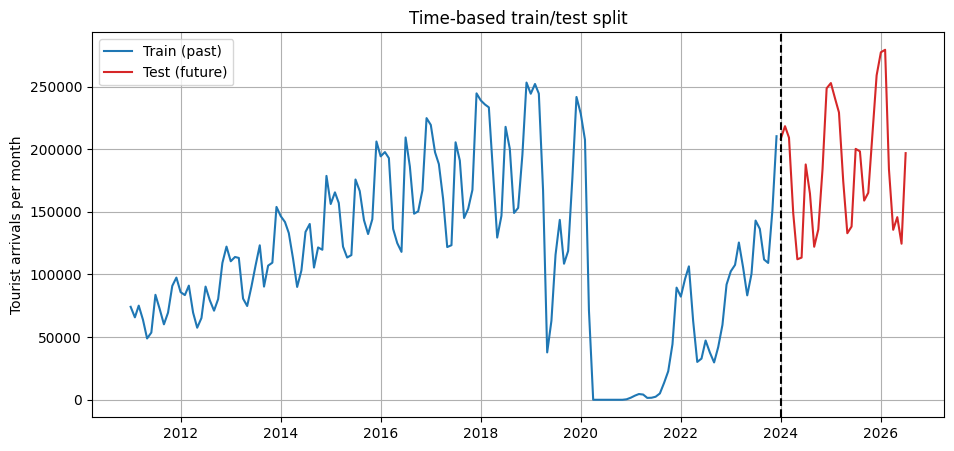

In [10]:
X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

fig, ax = plt.subplots()
ax.plot(train["date"], y_train, label="Train (past)")
ax.plot(test["date"], y_test, label="Test (future)", color="tab:red")
ax.axvline(pd.Timestamp("2024-01-01"), color="black", linestyle="--")
ax.set_title("Time-based train/test split")
ax.set_ylabel("Tourist arrivals per month")
ax.legend()
plt.show()

def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"MAE": round(mae), "RMSE": round(rmse), "MAPE %": round(mape, 1)}

**Notice:** the red test line reaches levels (up to about 279,000) **above anything in the training period** (maximum about 253,000). This matters a lot for tree-based models, as we see next.

## 6. Baselines and the first surprise: Random Forest
Simple baselines set the bar: **Naive** (this month = last month), **Seasonal naive** (this month = same month last year) and **Linear regression** on our features.

Then the first ensemble. A **Random Forest** builds hundreds of decision trees, each on a random sample of the data and a random subset of features (this is **bagging**), and **averages** their predictions. Averaging reduces **variance**: the model becomes more stable and less prone to overfitting.

In [11]:
base_results = {}
base_preds = {}
base_preds["Naive"] = test["lag_1"].values
base_preds["Seasonal naive"] = test["lag_12"].values
base_preds["Linear regression"] = LinearRegression().fit(X_train, y_train).predict(X_test)
rf_first = RandomForestRegressor(n_estimators=500, random_state=42).fit(X_train, y_train)
base_preds["Random Forest"] = rf_first.predict(X_test)

for name, p in base_preds.items():
    base_results[name] = evaluate(y_test, p)
pd.DataFrame(base_results).T

,MAE,RMSE,MAPE %
Naive,31821.0,41011.0,18.4
Seasonal naive,33971.0,41944.0,18.5
Linear regression,22189.0,27071.0,13.2
Random Forest,36006.0,42895.0,18.0


**Surprise:** the Random Forest is **not better than linear regression**. Its average error (MAE about 36,000) is even worse than the naive baseline. Instead of hiding this, we investigate it, because this is what "why does the model give this outcome?" means.

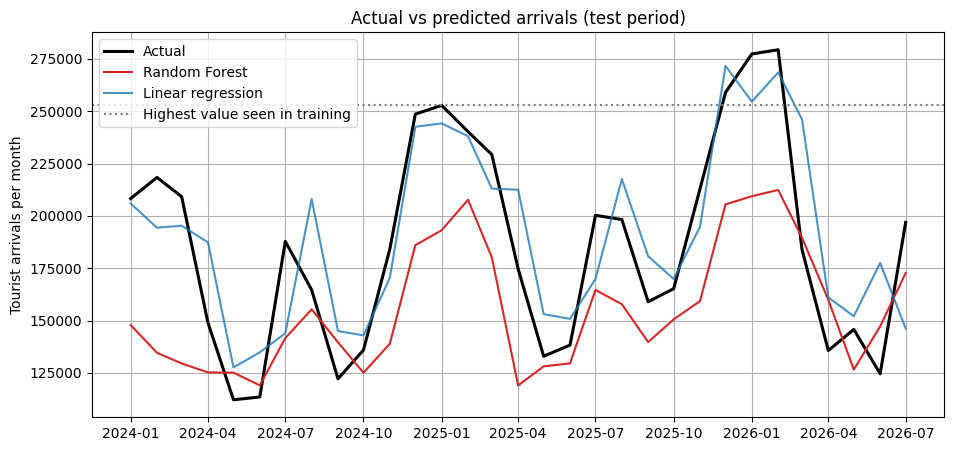

Test months higher than any training month: 3
Months where Random Forest under-predicts: 25 of 31


In [12]:
fig, ax = plt.subplots()
ax.plot(test["date"], y_test, label="Actual", color="black", linewidth=2.2)
ax.plot(test["date"], base_preds["Random Forest"], label="Random Forest", color="tab:red")
ax.plot(test["date"], base_preds["Linear regression"], label="Linear regression", color="tab:blue", alpha=0.8)
ax.axhline(y_train.max(), color="gray", linestyle=":", label="Highest value seen in training")
ax.set_title("Actual vs predicted arrivals (test period)")
ax.set_ylabel("Tourist arrivals per month")
ax.legend()
plt.show()

above = (y_test > y_train.max()).sum()
under = (base_preds["Random Forest"] < y_test.values).sum()
print(f"Test months higher than any training month: {above}")
print(f"Months where Random Forest under-predicts: {under} of {len(test)}")

**Why the Random Forest fails here:**
1. It **under-predicts in most months** (see the printed count).
2. A forest's prediction is an **average of values seen in training**, so it can **never exceed the highest training value** (the dotted line, about 253,000). Three test months (December 2025 to February 2026) were above that line.
3. Tourism in 2024 to 2026 grew to **record levels**. Tree models are good at patterns they have seen but weak at **trend and extrapolation**. A linear model extends a trend naturally.

**Plan:** keep the ensemble's strength (seasonality and non-linear patterns) but give it help with the trend, using **hybrid models**.

## 7. All ensemble families, plus hybrids
**Bagging (reduces variance):** train many models on random samples and average them. *Random Forest* adds random feature subsets; *Extra Trees* even picks split thresholds at random; *Bagging* is the plain version.

**Boosting (reduces bias):** build trees one after another, each correcting the mistakes of the previous ones. *AdaBoost* re-weights badly predicted examples; *Gradient Boosting* fits the residuals; *XGBoost* adds regularisation; *LightGBM* is a fast histogram-based version (with little data we allow small leaves); *CatBoost* uses ordered boosting and symmetric trees to resist overfitting.

**Combining:** *Voting* averages different models; *Stacking* feeds model predictions into a final Ridge regression. (scikit-learn builds stacking inputs with 5 contiguous folds, so in a strict time-series setting it can use some "future" folds, and we treat stacking with extra caution.)

**Hybrid models (the key idea):**
1. a **linear regression** learns the level and growth trend;
2. we compute its **residuals** (what it missed in training);
3. an **ensemble learns the residuals** (seasonal and non-linear patterns);
4. prediction = linear prediction + ensemble correction.

Linear models extrapolate but miss complex patterns; trees capture complex patterns but cannot extrapolate. Each covers the other's weakness. We build a hybrid version of **every** ensemble, so each can be compared with and without the trend model.

In [13]:
class HybridRegressor(BaseEstimator, RegressorMixin):
    def __init__(self, model=None):
        self.model = model

    def fit(self, X, y):
        self.trend_ = LinearRegression().fit(X, y)                  # step 1: trend
        residuals = y - self.trend_.predict(X)                      # step 2: what it missed
        self.model_ = clone(self.model).fit(X, residuals)           # step 3: ensemble learns leftovers
        return self

    def predict(self, X):
        return self.trend_.predict(X) + self.model_.predict(X)      # step 4: add them

In [14]:
raw_models = {
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=300, random_state=42),
    "Bagging (trees)": BaggingRegressor(DecisionTreeRegressor(), n_estimators=200, random_state=42),
    "AdaBoost": AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=200,
                                  learning_rate=0.05, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                   subsample=0.8, random_state=42),
}
try:
    from xgboost import XGBRegressor
    raw_models["XGBoost"] = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                         subsample=0.8, random_state=42)
except Exception as e:
    print("XGBoost not available:", e)
try:
    from lightgbm import LGBMRegressor
    raw_models["LightGBM"] = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15,
                                           min_child_samples=5, random_state=42, verbose=-1)
except Exception as e:
    print("LightGBM not available:", e)
try:
    from catboost import CatBoostRegressor
    raw_models["CatBoost"] = CatBoostRegressor(iterations=300, learning_rate=0.05, depth=4,
                                               random_seed=42, verbose=0)
except Exception as e:
    print("CatBoost not available:", e)

trees3 = [("rf", RandomForestRegressor(n_estimators=200, random_state=42)),
          ("et", ExtraTreesRegressor(n_estimators=200, random_state=42)),
          ("gb", GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3,
                                           subsample=0.8, random_state=42))]
raw_models["Voting (RF+ET+GB)"] = VotingRegressor(trees3)
raw_models["Stacking (RF+ET+GB)"] = StackingRegressor(estimators=trees3, final_estimator=RidgeCV(), cv=5)

# Every ensemble also gets a hybrid version
hybrid_models = {f"Hybrid: Linear + {k}": HybridRegressor(v) for k, v in raw_models.items()}
all_models = {"Linear regression": LinearRegression(), **raw_models, **hybrid_models}
print(len(all_models), "models ready")

21 models ready


## 8. Main comparison (train to Dec 2023, test Jan 2024 to Jul 2026)
All models use the same features, training period and test period.

In [15]:
results, preds, family = {}, {}, {}

def record(name, fam, y_pred):
    preds[name] = np.asarray(y_pred)
    results[name] = evaluate(y_test.values, preds[name])
    family[name] = fam

record("Naive", "Baseline", test["lag_1"].values)
record("Seasonal naive", "Baseline", test["lag_12"].values)

def family_of(name):
    if name == "Linear regression": return "Baseline"
    if name.startswith("Hybrid"): return "Hybrid"
    if name.startswith(("Voting", "Stacking")): return "Combining"
    if name in ("Random Forest", "Extra Trees", "Bagging (trees)"): return "Bagging"
    return "Boosting"

for name, m in all_models.items():
    record(name, family_of(name), clone(m).fit(X_train, y_train).predict(X_test))

table = pd.DataFrame(results).T
table["Family"] = pd.Series(family)
table = table.sort_values("MAE")
table

,MAE,RMSE,MAPE %,Family
Hybrid: Linear + Voting (RF+ET+GB),13078.0,20428.0,7.7,Hybrid
Hybrid: Linear + Extra Trees,13831.0,20782.0,8.1,Hybrid
Hybrid: Linear + Gradient Boosting,14722.0,22947.0,8.7,Hybrid
Hybrid: Linear + XGBoost,14917.0,23001.0,8.8,Hybrid
Hybrid: Linear + Bagging (trees),15025.0,20468.0,8.9,Hybrid
Hybrid: Linear + CatBoost,15326.0,22312.0,9.1,Hybrid
Hybrid: Linear + Random Forest,15382.0,20832.0,9.1,Hybrid
Hybrid: Linear + Stacking (RF+ET+GB),15421.0,21354.0,9.2,Hybrid
Hybrid: Linear + LightGBM,15842.0,23557.0,9.5,Hybrid
Hybrid: Linear + AdaBoost,16827.0,23376.0,10.1,Hybrid


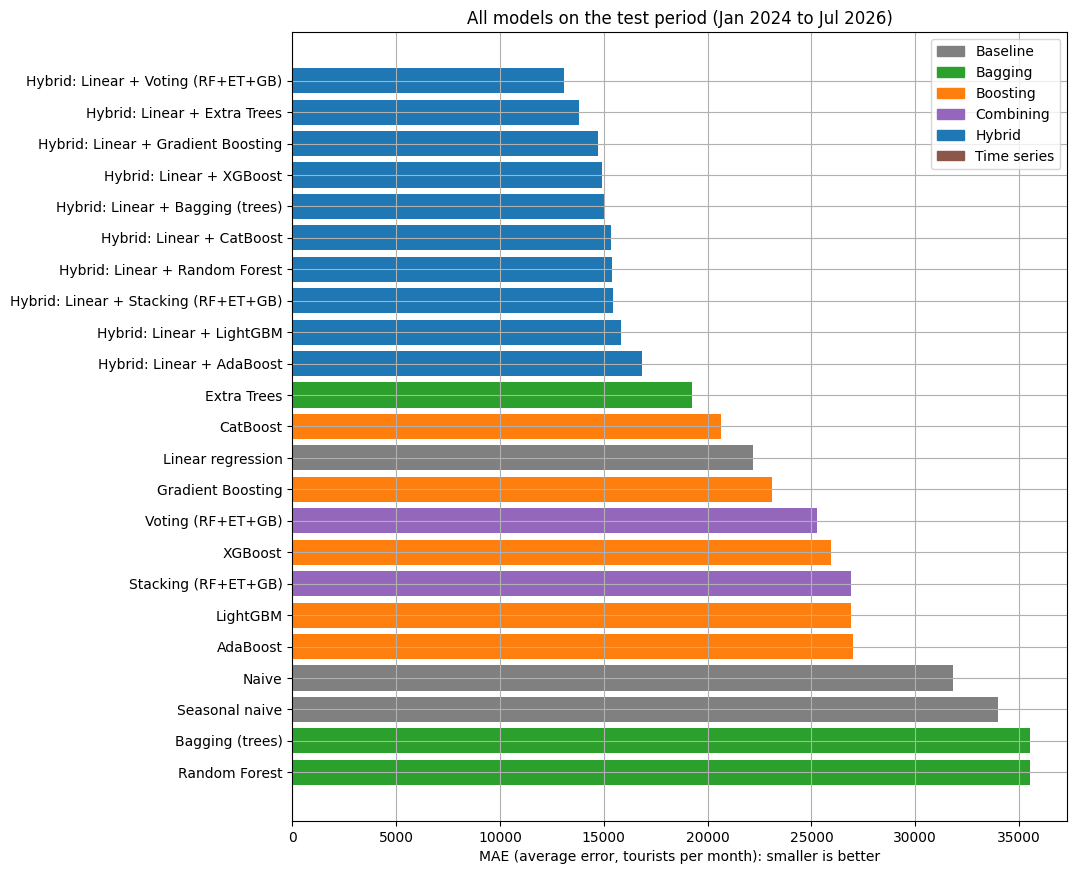

In [16]:
colors = {"Baseline": "gray", "Bagging": "tab:green", "Boosting": "tab:orange",
          "Combining": "tab:purple", "Hybrid": "tab:blue", "Time series": "tab:brown"}
t = table.sort_values("MAE", ascending=False)
fig, ax = plt.subplots(figsize=(10, 0.38 * len(t) + 1.5))
ax.barh(t.index, t["MAE"], color=[colors[f] for f in t["Family"]])
ax.set_xlabel("MAE (average error, tourists per month): smaller is better")
ax.set_title("All models on the test period (Jan 2024 to Jul 2026)")
ax.legend(handles=[Patch(color=c, label=f) for f, c in colors.items()], loc="upper right")
plt.show()

**Raw ensemble vs hybrid (the same ensemble with and without the trend model):**

In [17]:
rows = []
for name in raw_models:
    raw = results[name]["MAE"]
    hyb = results[f"Hybrid: Linear + {name}"]["MAE"]
    rows.append({"Ensemble": name, "Raw MAE": raw, "Hybrid MAE": hyb,
                 "Improvement %": round((raw - hyb) / raw * 100, 1)})
pd.DataFrame(rows).set_index("Ensemble")

,Raw MAE,Hybrid MAE,Improvement %
Ensemble,,,
Random Forest,35538,15382,56.7
Extra Trees,19249,13831,28.1
Bagging (trees),35529,15025,57.7
AdaBoost,27021,16827,37.7
Gradient Boosting,23099,14722,36.3
XGBoost,25951,14917,42.5
LightGBM,26914,15842,41.1
CatBoost,20633,15326,25.7
Voting (RF+ET+GB),25274,13078,48.3


**What we see (from our run):**
- Every hybrid beats its raw version, and the best hybrids have an average error of about 13,000 to 15,000 tourists, against about 19,000 to 36,000 for the raw ensembles.
- The raw tree ensembles that did best (Extra Trees, CatBoost) still lost to the hybrids.
- The raw Random Forest, Bagging, Stacking and several boosters struggle with the record-high months, for the reason explained in Section 6.

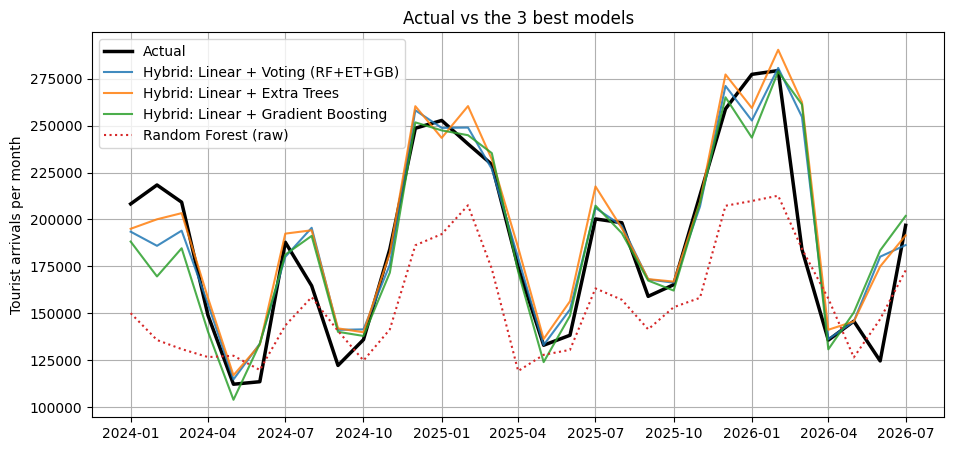

In [18]:
best = [n for n in table.index if family[n] != "Baseline"][:3]
fig, ax = plt.subplots()
ax.plot(test["date"], y_test, color="black", linewidth=2.5, label="Actual")
for n in best:
    ax.plot(test["date"], preds[n], label=n, alpha=0.85)
ax.plot(test["date"], preds["Random Forest"], color="tab:red", linestyle=":", label="Random Forest (raw)")
ax.set_title("Actual vs the 3 best models")
ax.set_ylabel("Tourist arrivals per month")
ax.legend()
plt.show()

**Errors by monsoon season** (average error in each season of the test period):

In [19]:
season_test = test["season"].values
season_table = {}
for n in ["Naive", "Linear regression", "Random Forest"] + best:
    err = np.abs(y_test.values - preds[n])
    season_table[n] = pd.Series(err).groupby(season_test).mean().round()
pd.DataFrame(season_table).T

,Inter_monsoon,NE_monsoon,SW_monsoon
Naive,39473.0,19971.0,33228.0
Linear regression,23742.0,11191.0,27763.0
Random Forest,35477.0,60306.0,20342.0
Hybrid: Linear + Voting (RF+ET+GB),12055.0,13471.0,13623.0
Hybrid: Linear + Extra Trees,12345.0,15018.0,14244.0
Hybrid: Linear + Gradient Boosting,14539.0,15295.0,14510.0


The raw Random Forest is worst in the North-East monsoon (December to February), the peak months that reached record levels. The hybrids have much more even errors across the three seasons.

## 9. Hybrid with a classic time-series model (SARIMA), tested fairly
**SARIMA** is the classic seasonal time-series model (ARIMA with a yearly seasonal part).

**A fairness problem.** Our machine learning models forecast **one month ahead** and see the real previous months. A normal SARIMA `forecast()` predicts all 31 test months **at once, without seeing any 2024 to 2026 data**. That is a much harder task, so the comparison would be unfair. We therefore evaluate SARIMA **both ways**:
- **31 months ahead** (`forecast`), no new data
- **1 month ahead** (`extend`): the same fitted parameters, but the model sees each new month after it happens, like the ML models

**Three versions:** A (shock flag as an extra input), B (shock months treated as *missing* so SARIMA learns only from normal months), D (as B, with a simpler seasonal part). A **SARIMA + Random Forest hybrid** adds a Random Forest that learns SARIMA's training errors.

In [20]:
sarima_table = None
try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX

    y_all = train[target].astype(float).values
    shock_tr = train["shock"].values.astype(bool)
    y_test_vals = test[target].astype(float).values
    sarima_rows, sarima_store = {}, {}

    def run_sarima(name, use_missing, seasonal):
        y = y_all.copy()
        exog_tr = exog_te = None
        if use_missing:
            y[shock_tr] = np.nan
        else:
            exog_tr, exog_te = train[["shock"]].values, test[["shock"]].values
        res = SARIMAX(y, exog=exog_tr, order=(1, 1, 1), seasonal_order=seasonal,
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

        multi = np.asarray(res.forecast(steps=len(test), exog=exog_te))        # 31 months ahead
        ext = res.extend(y_test_vals, exog=exog_te)                            # same parameters, sees new months
        one = np.asarray(ext.fittedvalues)                                     # 1 month ahead
        assert len(one) == len(test)

        # hybrid: Random Forest learns SARIMA's training errors (skip first 13 and missing months)
        valid = np.arange(len(y_all)) >= 13
        if use_missing:
            valid &= ~shock_tr
        resid = y_all - np.asarray(res.fittedvalues)
        rf_h = RandomForestRegressor(n_estimators=500, random_state=42).fit(train[features][valid], resid[valid])
        hyb_one = one + rf_h.predict(test[features])

        sarima_rows[f"{name}: 31 months ahead"] = evaluate(y_test_vals, multi)
        sarima_rows[f"{name}: 1 month ahead"] = evaluate(y_test_vals, one)
        sarima_rows[f"{name} + RF: 1 month ahead"] = evaluate(y_test_vals, hyb_one)
        sarima_store[f"{name}: 1 month ahead"] = one
        sarima_store[f"{name} + RF: 1 month ahead"] = hyb_one

    for v in [("A. Shock flag as input", False, (0, 1, 1, 12)),
              ("B. Shock months missing", True, (0, 1, 1, 12)),
              ("D. Missing + simple seasonal", True, (1, 0, 0, 12))]:
        try:
            run_sarima(*v)
        except Exception as e:
            print("Variant failed:", v[0], "->", e)

    sarima_table = pd.DataFrame(sarima_rows).T.sort_values("MAE")
    print(sarima_table.to_string())
except Exception as e:
    print("SARIMA section could not run:", e)

                                                      MAE     RMSE  MAPE %
A. Shock flag as input: 1 month ahead             16786.0  23931.0     9.9
A. Shock flag as input + RF: 1 month ahead        17595.0  23653.0    10.2
D. Missing + simple seasonal: 1 month ahead       18990.0  25973.0    11.4
B. Shock months missing: 1 month ahead            19599.0  27666.0    11.8
D. Missing + simple seasonal + RF: 1 month ahead  26508.0  32830.0    16.4
B. Shock months missing + RF: 1 month ahead       27905.0  36354.0    17.0
B. Shock months missing: 31 months ahead          31570.0  44958.0    16.0
D. Missing + simple seasonal: 31 months ahead     32842.0  45865.0    15.9
A. Shock flag as input: 31 months ahead           36711.0  48615.0    24.2


**How to read this table:** compare each version's "31 months ahead" row with its "1 month ahead" row. The difference shows how unfair the first test was for SARIMA. Then compare the **1 month ahead** rows with the machine learning models in the Section 8 table: that is the fair comparison.

In [21]:
# Add the best 1-month-ahead SARIMA results to the main comparison
try:
    one_rows = [n for n in sarima_table.index if "1 month ahead" in n]
    best_s = [n for n in one_rows if "+ RF" not in n][0]
    best_h = [n for n in one_rows if "+ RF" in n][0]
    record("SARIMA (1 month ahead)", "Time series", sarima_store[best_s])
    record("Hybrid: SARIMA + Random Forest", "Hybrid", sarima_store[best_h])
    print("Added:", best_s, "|", best_h)
    table = pd.DataFrame(results).T
    table["Family"] = pd.Series(family)
    table = table.sort_values("MAE")
    display(table)
except Exception as e:
    print("Could not add SARIMA to the main table:", e)

Added: A. Shock flag as input: 1 month ahead | A. Shock flag as input + RF: 1 month ahead


,MAE,RMSE,MAPE %,Family
Hybrid: Linear + Voting (RF+ET+GB),13078.0,20428.0,7.7,Hybrid
Hybrid: Linear + Extra Trees,13831.0,20782.0,8.1,Hybrid
Hybrid: Linear + Gradient Boosting,14722.0,22947.0,8.7,Hybrid
Hybrid: Linear + XGBoost,14917.0,23001.0,8.8,Hybrid
Hybrid: Linear + Bagging (trees),15025.0,20468.0,8.9,Hybrid
Hybrid: Linear + CatBoost,15326.0,22312.0,9.1,Hybrid
Hybrid: Linear + Random Forest,15382.0,20832.0,9.1,Hybrid
Hybrid: Linear + Stacking (RF+ET+GB),15421.0,21354.0,9.2,Hybrid
Hybrid: Linear + LightGBM,15842.0,23557.0,9.5,Hybrid
SARIMA (1 month ahead),16786.0,23931.0,9.9,Time series


## 10. Is the ranking reliable? Rolling backtest
One test window can be lucky. We repeat the test on **five windows**. For each, we train on *all data before it* and test on the window, so the model never sees the future.

| Window | Test period | Type of period |
|---|---|---|
| 2016, 2017, 2018 | 12 months each | Steady growth after the war |
| 2023 | 12 months | Recovery from COVID and the crisis |
| 2024-26 | 31 months | Main test from Section 8 |

We do not use 2019 to 2022 as *test* windows because the shock flag would tell the model about events (the Easter attacks, COVID) that nobody could know in advance.

In [22]:
windows = [("2016", "2016-01-01", "2017-01-01"),
           ("2017", "2017-01-01", "2018-01-01"),
           ("2018", "2018-01-01", "2019-01-01"),
           ("2023", "2023-01-01", "2024-01-01"),
           ("2024-26", "2024-01-01", "2100-01-01")]

bt = {}
for wname, start, end in windows:
    tr = data[data["date"] < start]
    te = data[(data["date"] >= start) & (data["date"] < end)]
    row = {"Naive": mean_absolute_error(te[target], te["lag_1"]),
           "Seasonal naive": mean_absolute_error(te[target], te["lag_12"])}
    for name, m in all_models.items():
        fitted = clone(m).fit(tr[features], tr[target])
        row[name] = mean_absolute_error(te[target], fitted.predict(te[features]))
    bt[wname] = row
    print("done:", wname, "| train", len(tr), "months, test", len(te), "months")

backtest = pd.DataFrame(bt)
backtest["Mean MAE"] = backtest.mean(axis=1)
backtest["Mean rank"] = backtest[[w[0] for w in windows]].rank().mean(axis=1)
backtest = backtest.sort_values("Mean MAE")
backtest.round(0).assign(**{"Mean rank": backtest["Mean rank"].round(1)})

done: 2016 | train 60 months, test 12 months
done: 2017 | train 72 months, test 12 months
done: 2018 | train 84 months, test 12 months
done: 2023 | train 144 months, test 12 months
done: 2024-26 | train 156 months, test 31 months


,2016,2017,2018,2023,2024-26,Mean MAE,Mean rank
Hybrid: Linear + Voting (RF+ET+GB),11416.0,16192.0,16140.0,11700.0,13078.0,13705.0,6.2
Hybrid: Linear + Extra Trees,11473.0,15545.0,16670.0,12209.0,13831.0,13946.0,7.8
Hybrid: Linear + Bagging (trees),10847.0,16670.0,15751.0,11865.0,15025.0,14032.0,7.2
Hybrid: Linear + Random Forest,10999.0,16621.0,15801.0,12044.0,15382.0,14169.0,8.2
Hybrid: Linear + XGBoost,11366.0,16563.0,16597.0,11705.0,14917.0,14230.0,8.4
Hybrid: Linear + Gradient Boosting,12033.0,16299.0,16935.0,11487.0,14722.0,14295.0,8.8
Hybrid: Linear + CatBoost,11701.0,15976.0,16562.0,12681.0,15326.0,14449.0,9.0
Hybrid: Linear + AdaBoost,11892.0,16785.0,16398.0,14160.0,16827.0,15212.0,11.8
Hybrid: Linear + LightGBM,10582.0,16400.0,17787.0,16594.0,15842.0,15441.0,10.4
Hybrid: Linear + Stacking (RF+ET+GB),10694.0,24143.0,13634.0,15142.0,15421.0,15807.0,8.6


**How to read the table:** each number is the average error (MAE) in that window; "Mean MAE" averages the five windows; "Mean rank" is the average position (1 = best), so one lucky window cannot dominate.

**What we found (from our run):**
1. **All 10 hybrids have a lower mean error than every raw ensemble and than linear regression** (the Stacking hybrid only just: about 15,800 against 15,900). The best was *Hybrid: Linear + Voting* (mean MAE about 13,700, best mean rank), followed by Extra Trees, Bagging, Random Forest, XGBoost, Gradient Boosting and CatBoost hybrids (about 13,900 to 14,500).
2. **Raw tree ensembles fail badly in the 2023 recovery window** (about 33,000 to 34,000 for Random Forest, Extra Trees, Gradient Boosting and Voting). Tourism was recovering fast from a very low base, and trees trained on the past cannot extrapolate.
3. **There is no single winner in every window.** Linear regression was best in 2016 and 2018 (about 10,500 and 10,300), where a straight trend is enough, and seasonal naive was best in 2017 (about 8,000).

**Honest conclusion:** hybrids are the best *on average* and the most *reliable*, especially in difficult periods (recovery and record highs), but not the best in every single window.

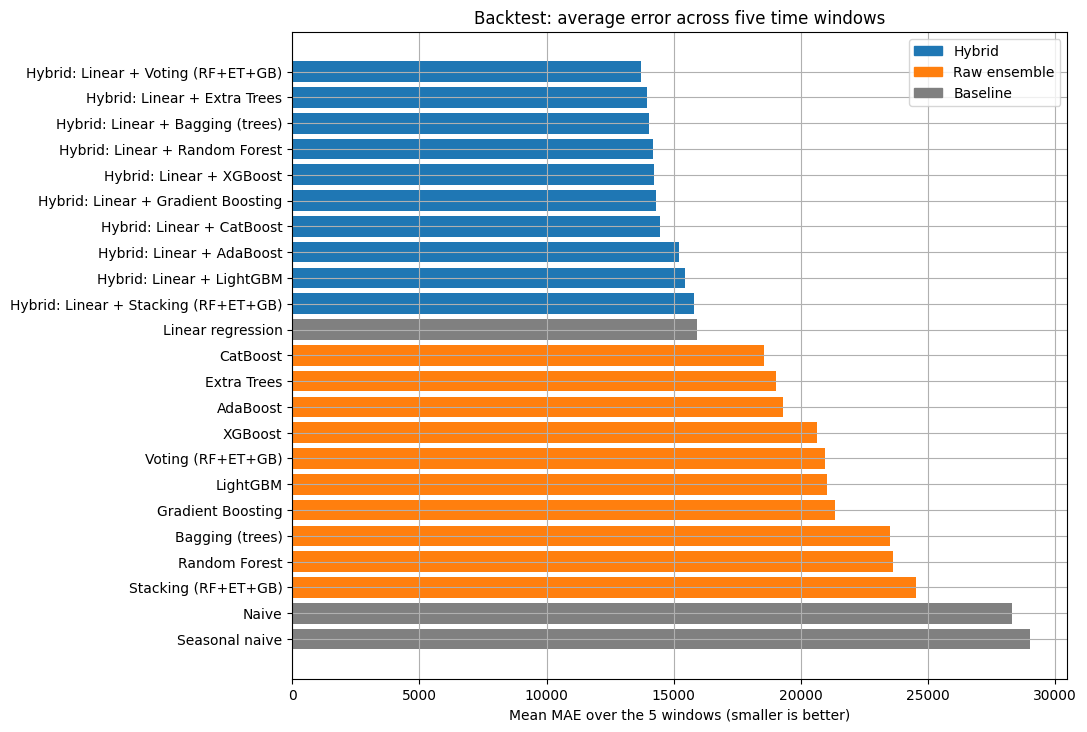

In [23]:
fig, ax = plt.subplots(figsize=(10, 0.3 * len(backtest) + 1.5))
plot_df = backtest["Mean MAE"].sort_values(ascending=False)
cols = ["tab:blue" if n.startswith("Hybrid") else ("gray" if n in ("Naive", "Seasonal naive", "Linear regression") else "tab:orange")
        for n in plot_df.index]
ax.barh(plot_df.index, plot_df.values, color=cols)
ax.set_xlabel("Mean MAE over the 5 windows (smaller is better)")
ax.set_title("Backtest: average error across five time windows")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="tab:blue", label="Hybrid"), Patch(color="tab:orange", label="Raw ensemble"),
                   Patch(color="gray", label="Baseline")], loc="upper right")
plt.show()

## 11. Which feature groups matter? (feature-group test)
We take **Hybrid: Linear + Extra Trees**, remove one group of features at a time and repeat the five-window backtest. If the error rises a lot, the group matters. (In the "no past values" test we add a time index `t`, otherwise the linear part could not see the trend.)

In [24]:
cal = ["month", "quarter", "month_sin", "month_cos", "season_SW_monsoon", "season_NE_monsoon", "season_Inter_monsoon"]
past = ["lag_1", "lag_2", "lag_3", "lag_12", "roll3", "roll12"]
fxf = ["fx_lag1", "fx_chg_lag1"]

feature_sets = {
    "All 16 features": features,
    "No calendar/season": [f for f in features if f not in cal],
    "No past values (+ time index t)": cal + ["shock"] + fxf + ["t"],
    "No exchange rate": [f for f in features if f not in fxf],
    "No shock flag": [f for f in features if f != "shock"],
    "Past values + shock only": past + ["shock"],
}

ablation = {}
for set_name, fs in feature_sets.items():
    row = {}
    for wname, start, end in windows:
        tr = data[data["date"] < start]
        te = data[(data["date"] >= start) & (data["date"] < end)]
        m = HybridRegressor(ExtraTreesRegressor(n_estimators=300, random_state=42)).fit(tr[fs], tr[target])
        row[wname] = mean_absolute_error(te[target], m.predict(te[fs]))
    row["Mean MAE"] = np.mean(list(row.values()))
    ablation[set_name] = row

ablation = pd.DataFrame(ablation).T
ablation.round(0)

,2016,2017,2018,2023,2024-26,Mean MAE
All 16 features,11473.0,15545.0,16670.0,12209.0,13831.0,13946.0
No calendar/season,10007.0,15168.0,17508.0,23953.0,18954.0,17118.0
No past values (+ time index t),10918.0,15712.0,11728.0,114977.0,26958.0,36058.0
No exchange rate,11070.0,15976.0,15719.0,15231.0,13671.0,14333.0
No shock flag,11497.0,15844.0,16538.0,22644.0,17174.0,16739.0
Past values + shock only,9484.0,15401.0,15848.0,26327.0,17232.0,16858.0


**What we found (from our run):**

| Removed | Mean MAE | Meaning |
|---|---|---|
| Nothing (all 16 features) | about 13,900 | Reference |
| Exchange rate | about 14,300 | **Small effect.** The exchange rate adds little. |
| Shock flag | about 16,700 | **Clear effect**, mostly in 2023 (COVID zeros in the training data confuse the model) |
| Calendar/season | about 17,100 | **Clear effect**, mostly in 2023 and 2024-26 |
| Past values (lags, rolling) | about 36,100 | **Huge effect.** Without recent history the model collapses (over 100,000 error in 2023) |

**Meaning:** recent history is by far the most important information (tourism this month is mostly "last month, adjusted for the time of year"); month and season matter, especially in recent windows, which supports using the monsoon seasons; the exchange rate is a weak predictor here. In the two earliest windows, removing season features sometimes helped slightly: with only 5 to 6 years of training data, extra features can add noise.

## 12. Feature importance of the best hybrid
**Permutation importance:** shuffle a feature's values randomly and see how much the error grows. A large increase means the model depends on it.

*A caution about the calendar features:* month, quarter, sine, cosine and the season columns **overlap with each other**, so the linear part's coefficients for them are unstable (they change between computers and library versions, although the predictions hardly change). Shuffling one of them alone can therefore give misleading numbers. We avoid this by shuffling **whole groups of related features together**.

Hybrid: Linear + Voting -> MAE on the test period: 13078


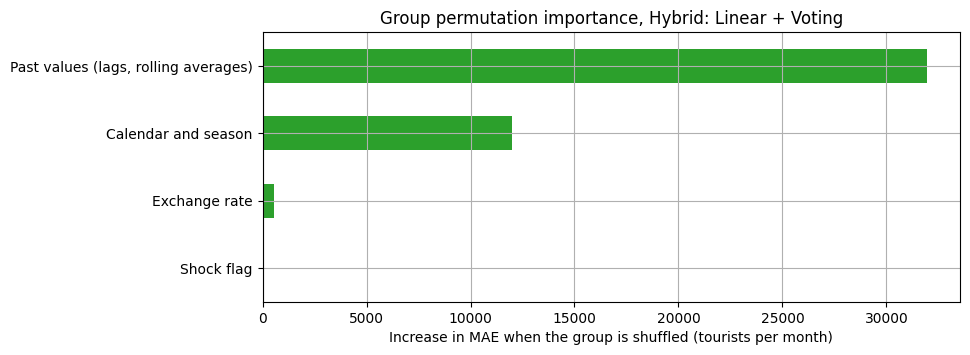

Past values (lags, rolling averages)    31949.0
Calendar and season                     12009.0
Exchange rate                             557.0
Shock flag                                  0.0

Individual lag features:
lag_1     34232.0
lag_2     19766.0
lag_12     6069.0


In [25]:
best_model = HybridRegressor(VotingRegressor(trees3)).fit(train[features], train[target])
base_mae = mean_absolute_error(test[target], best_model.predict(test[features]))
pred_best = best_model.predict(test[features])
print("Hybrid: Linear + Voting -> MAE on the test period:", round(base_mae))

groups = {"Past values (lags, rolling averages)": past,
          "Calendar and season": cal,
          "Shock flag": ["shock"],
          "Exchange rate": fxf}
rng = np.random.default_rng(42)
group_imp = {}
for gname, cols in groups.items():
    increases = []
    for _ in range(30):
        Xp = test[features].copy()
        Xp[cols] = Xp[cols].values[rng.permutation(len(Xp))]     # shuffle the whole group together
        increases.append(mean_absolute_error(test[target], best_model.predict(Xp)) - base_mae)
    group_imp[gname] = np.mean(increases)

group_imp = pd.Series(group_imp).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.5))
group_imp.plot.barh(ax=ax, color="tab:green")
ax.set_xlabel("Increase in MAE when the group is shuffled (tourists per month)")
ax.set_title("Group permutation importance, Hybrid: Linear + Voting")
plt.show()
print(group_imp.sort_values(ascending=False).round(0).to_string())

# Single lag features are not overlapping with each other as strongly, so show them individually
pi = permutation_importance(best_model, test[features], test[target],
                            scoring="neg_mean_absolute_error", n_repeats=20, random_state=42)
single = pd.Series(pi.importances_mean, index=features)
print("\nIndividual lag features:")
print(single[["lag_1", "lag_2", "lag_12"]].round(0).to_string())

**Reading the result:** past values are the most important group, then calendar and season, with the shock flag and the exchange rate far behind. Among single features, `lag_1` (last month) and `lag_2` matter most, with `lag_12` (same month last year) next. This agrees with the feature-group test in Section 11: **recent history first, season second, exchange rate last.** Note that the shock flag is irrelevant *in the test period*, because it is 0 for every test month, but it is important *in training*, as Section 11 shows.

## 13. Explaining individual predictions with SHAP
Permutation importance is global. **SHAP** explains **one prediction**: it shows how much each feature pushed that month's forecast up or down. Our hybrid has two parts, so there are two explanations: the **linear trend part** (its coefficients) and the **tree correction part** (SHAP). We use **Hybrid: Linear + Extra Trees**, because SHAP's tree explainer works on a single tree ensemble.

In [26]:
hy_et = HybridRegressor(ExtraTreesRegressor(n_estimators=300, random_state=42)).fit(train[features], train[target])

coef = pd.Series(hy_et.trend_.coef_, index=features).round(2)
print("Linear (trend) part: coefficient per unit of each feature")
print(coef.to_string())

Linear (trend) part: coefficient per unit of each feature
month                    5663.53
quarter                 -8317.40
month_sin               -9268.19
month_cos              -18148.66
season_SW_monsoon      -28068.89
season_NE_monsoon       33441.57
season_Inter_monsoon    -5372.69
shock                  -26489.34
lag_1                       0.90
lag_2                      -0.55
lag_3                       0.18
lag_12                      0.08
roll3                       0.17
roll12                      0.11
fx_lag1                    71.54
fx_chg_lag1              8100.90


`lag_1` has a coefficient of about 0.9: the linear part says "next month is about 90% of last month, plus adjustments". The `shock` coefficient is large and negative because shock months had very low arrivals. The calendar and season coefficients overlap, so read them as a group, not one by one.

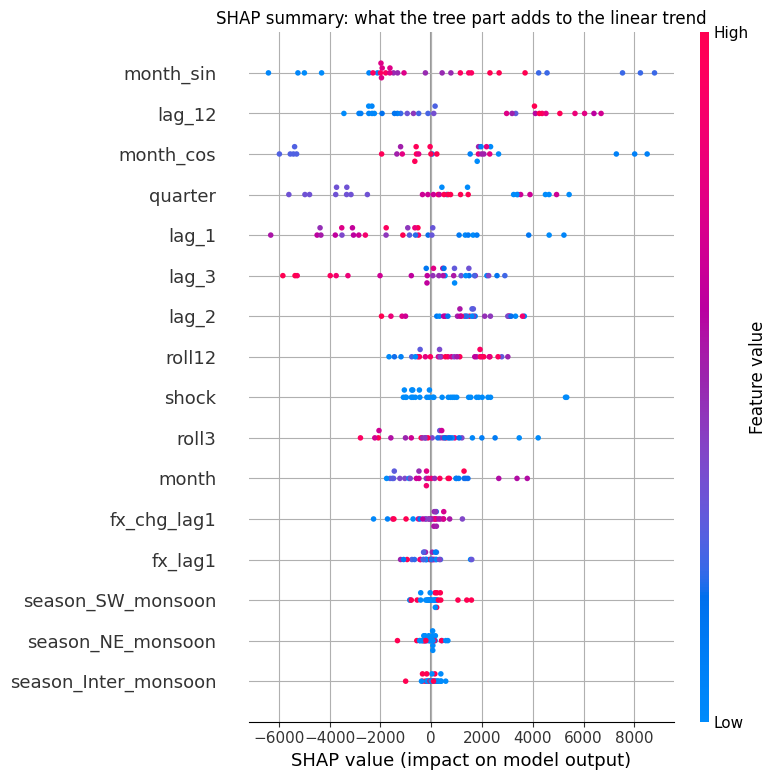

In [27]:
try:
    import shap
    explainer = shap.TreeExplainer(hy_et.model_)
    sv = explainer.shap_values(test[features])

    shap.summary_plot(sv, test[features], show=False)
    plt.title("SHAP summary: what the tree part adds to the linear trend")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("SHAP part could not run:", e)

**How to read the SHAP summary plot:** each dot is one month. Left or right = how much that feature lowered or raised the tree part's correction. Red = high feature value, blue = low. In our run the corrections are fairly small (up to about ±8,000 tourists), and the most important features are `month_sin`, `lag_12` and `month_cos`: **the tree part mainly adds the yearly seasonal pattern on top of the linear trend.**

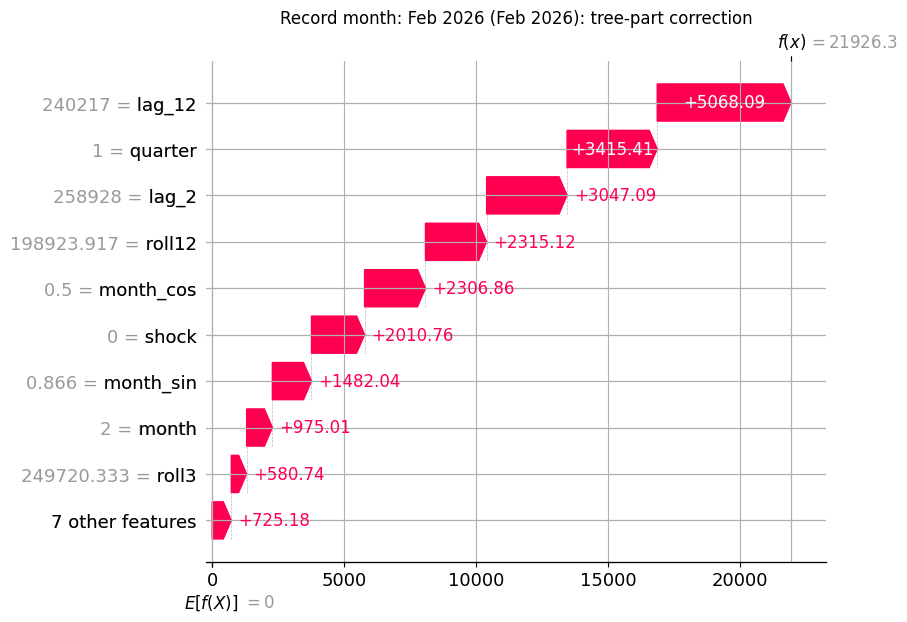

Record month: Feb 2026 -> actual: 279328 | predicted: 290433


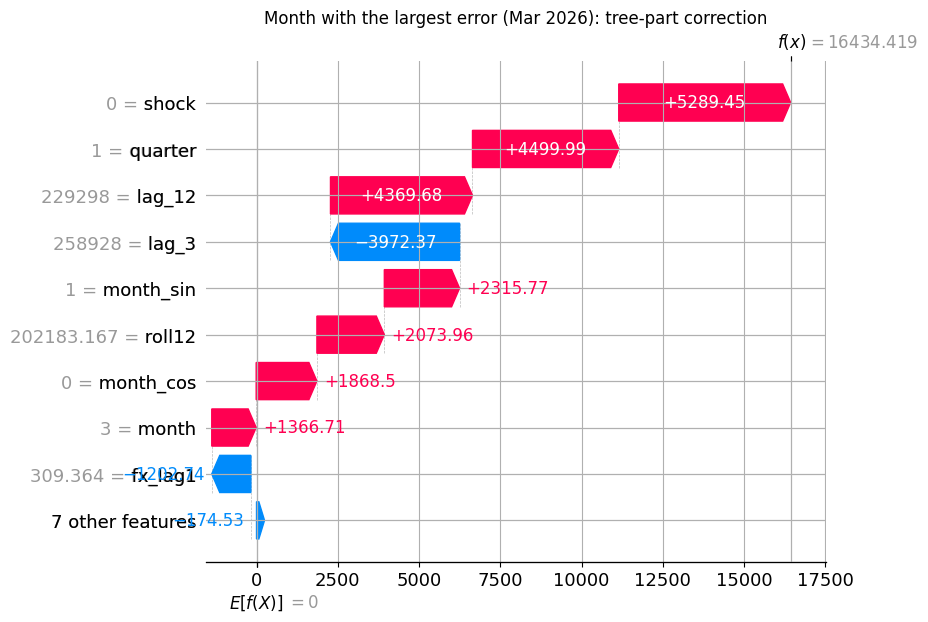

Month with the largest error -> actual: 183979 | predicted: 262540


In [28]:
try:
    base = float(np.ravel(explainer.expected_value)[0])
    abs_err = np.abs(test[target].values - hy_et.predict(test[features]))
    worst_i = int(np.argmax(abs_err))
    feb26_i = int(np.where(test["date"].dt.strftime("%Y-%m") == "2026-02")[0][0])

    for label, i in [("Record month: Feb 2026", feb26_i), ("Month with the largest error", worst_i)]:
        shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=base,
                                              data=test[features].iloc[i].values,
                                              feature_names=features), show=False)
        plt.title(f"{label} ({test['date'].iloc[i].strftime('%b %Y')}): tree-part correction")
        plt.show()
        print(label, "-> actual:", int(test[target].iloc[i]),
              "| predicted:", round(float(hy_et.predict(test[features].iloc[[i]])[0])))
except Exception as e:
    print("SHAP waterfall could not run:", e)

**How to read a waterfall plot:** it starts from the average correction, and each bar shows how one feature pushed this month's correction up (red) or down (blue). The two months shown are the record month (February 2026) and the month with the largest error.

## 14. Where does the best model make its mistakes?

In [29]:
err = test.copy()
err["pred_hybrid"] = pred_best
err["pred_linear"] = LinearRegression().fit(train[features], train[target]).predict(test[features])
err["pred_rf"] = RandomForestRegressor(n_estimators=300, random_state=42).fit(train[features], train[target]).predict(test[features])
err["change"] = err["arrivals"] / err["lag_1"] - 1
err["kind"] = np.where(err["change"].abs() >= 0.15, "Big move (15%+)", "Calm month")

summary = {}
for label, col in [("Hybrid: Linear + Voting", "pred_hybrid"), ("Linear regression", "pred_linear"), ("Random Forest (raw)", "pred_rf")]:
    e = (err[target] - err[col]).abs()
    summary[label] = e.groupby(err["kind"]).mean().round()
print(err["kind"].value_counts().to_string(), "\n")
print(pd.DataFrame(summary).T.to_string())

print("\nLargest errors of the hybrid:")
err["error"] = err[target] - err["pred_hybrid"]
err.sort_values("error", key=np.abs, ascending=False)[["date", "arrivals", "pred_hybrid", "error", "change"]].head(6).round(2)

kind
Calm month         16
Big move (15%+)    15 

kind                     Big move (15%+)  Calm month
Hybrid: Linear + Voting          11537.0     14523.0
Linear regression                27962.0     16777.0
Random Forest (raw)              31561.0     39266.0

Largest errors of the hybrid:


,date,arrivals,pred_hybrid,error,change
182,2026-03-01,183979,254634.05,-70655.05,-0.34
185,2026-06-01,124551,180125.73,-55574.73,-0.15
157,2024-02-01,218350,185922.39,32427.61,0.05
163,2024-08-01,164609,195524.77,-30915.77,-0.12
180,2026-01-01,277327,252713.48,24613.52,0.07
161,2024-06-01,113470,133747.12,-20277.12,0.01


**What we found (from our run):**
- The hybrid's error is **not higher in big-move months** (about 11,500) than in calm months (about 14,500).
- Its **largest errors are sudden drops**: **March 2026** (arrivals fell 34% from the previous month; the model predicted about 255,000, the real value was about 184,000) and **June 2026**. A model that sees only the past cannot know about an unusual event in that month. This is a *limit of forecasting from history*, not a coding error.
- The raw Random Forest is far worse than the hybrid in both kinds of month and worst in calm months (about 39,000), because it **under-predicts the level** almost everywhere.
- Linear regression is competitive in calm months (about 16,800) but about 28,000 off in big moves. The tree part of the hybrid repairs this.

## 15. Conclusions
1. **Hybrid models are the best choice for this problem.** A linear trend model plus an ensemble on its residuals beat every raw ensemble on the main test and had the lowest average error across five backtest windows.
2. **Raw tree ensembles fail on a rising trend**, because they can only average values seen in training. This is why a Random Forest was worse than the naive baseline in 2024 to 2026 and failed in the 2023 recovery window.
3. **What drives the forecasts:** recent history first, then month and monsoon season. The exchange rate adds very little.
4. **No model wins in every window.** In steady growth years, linear regression or seasonal naive can be best, so the conclusion is "best on average and most reliable", not "always best".
5. **The largest errors are sudden drops** that history cannot predict.
6. **SARIMA must be compared fairly.** Forecasting 31 months ahead without new data gave an error of about 36,700, but forecasting one month ahead, like the ML models, gave about 16,800. That is better than every raw ensemble (best raw: Extra Trees, about 19,200) and than linear regression (about 22,200), but behind nine of the ten hybrids (about 13,100 to 15,400 for the best ones). Adding a Random Forest to SARIMA's errors did not help (about 17,600). Treating shock months as missing helped the 31-month forecast but not the 1-month forecast.

## 16. Limitations (be honest about these in your report)
- **Small data:** 199 months, and a test period of 31 months. Differences between the top hybrids are small and may not be significant.
- **One-month-ahead forecasts only.** Forecasting several months ahead is harder.
- **The hybrid idea was motivated by what we saw in the test period** (the Random Forest failing there). The rolling backtest reduces, but does not remove, this risk.
- **Hindsight in the shock flag:** the flag labels past shocks that were not known in advance. It is used only for training; test months are never flagged.
- **Collinearity** among calendar features makes individual linear coefficients unstable (predictions are not affected).
- **No hyperparameter tuning:** models use reasonable fixed settings. Tuning with time-series cross-validation is a natural extension.
- **Few predictors:** no flight capacity, holidays, source-market or price data.
- **Stacking** uses ordinary 5-fold cross-validation inside scikit-learn, which is not strictly time-ordered.

## 17. References
- Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5-32.
- Geurts, P., Ernst, D., Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning*, 63, 3-42.
- Freund, Y., Schapire, R. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences*, 55, 119-139.
- Friedman, J. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29, 1189-1232.
- Chen, T., Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *KDD 2016*.
- Ke, G. et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS 2017*.
- Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
- Lundberg, S., Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS 2017*.
- Hyndman, R., Athanasopoulos, G. *Forecasting: Principles and Practice* (3rd ed.), OTexts.
- Data: Sri Lanka Tourism Development Authority (SLTDA) statistical and monthly reports; Central Bank of Sri Lanka (CBSL) exchange rate statistics.